# ANN LAB 03

**Name:** Muhammad Bilal  
**Reg No:** FA23-BAI-029

# Task 1

We load a standard binary classification dataset (the Iris dataset, filtering for two classes), inspect its shape, target, check for missing values, visualize class distribution, and split it into train and test sets.

Shape: (100, 5)
Missing values:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64
Target distribution:
 target
0    50
1    50
Name: count, dtype: int64


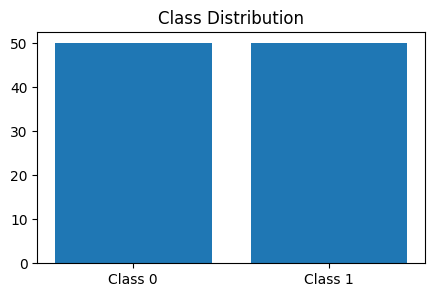

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

raw_data = load_iris()
X = raw_data.data[raw_data.target != 2]
y = raw_data.target[raw_data.target != 2]
y = np.where(y == 0, 0, 1)

df = pd.DataFrame(X, columns=raw_data.feature_names)
df['target'] = y

print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
print("Target distribution:\n", df['target'].value_counts())

plt.figure(figsize=(5, 3))
plt.bar(['Class 0', 'Class 1'], df['target'].value_counts())
plt.title("Class Distribution")
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Task 2

We implement a custom Perceptron classifier from scratch with weight initialization, prediction logic using a step function, training update rules, and accuracy evaluation.

In [11]:
class Perceptron:
    def __init__(self, input_dim, lr=0.1, epochs=100):
        self.w = np.zeros(input_dim)
        self.b = 0.0
        self.lr = lr
        self.epochs = epochs

    def predict(self, x):
        return np.where(np.dot(x, self.w) + self.b >= 0.0, 1, 0)

    def train(self, X, y):
        for _ in range(self.epochs):
            for xi, target in zip(X, y):
                update = self.lr * (target - self.predict(xi))
                self.w += update * xi
                self.b += update

p_model = Perceptron(input_dim=X_train.shape[1])
p_model.train(X_train, y_train)

preds = p_model.predict(X_test)
acc = np.mean(preds == y_test)
print("Test Accuracy:", acc)

Test Accuracy: 1.0


# Task 3

We modify the perceptron to track training error per epoch, plot the learning curve, print the final parameters, and visualize the decision boundary.

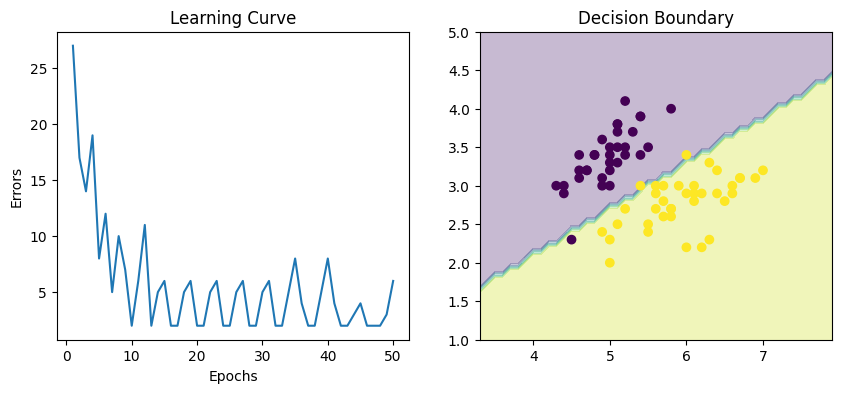

Final Weights: [ 3.63 -6.08]
Final Bias: -1.7000000000000004


In [12]:
class PerceptronWithTracking:
    def __init__(self, input_dim, lr=0.1, epochs=100):
        self.w = np.zeros(input_dim)
        self.b = 0.0
        self.lr = lr
        self.epochs = epochs
        self.errors = []

    def predict(self, x):
        return np.where(np.dot(x, self.w) + self.b >= 0.0, 1, 0)

    def train(self, X, y):
        for _ in range(self.epochs):
            err = 0
            for xi, target in zip(X, y):
                update = self.lr * (target - self.predict(xi))
                self.w += update * xi
                self.b += update
                err += int(update != 0.0)
            self.errors.append(err)

X_train_2d = X_train[:, :2]
X_test_2d = X_test[:, :2]

p_track = PerceptronWithTracking(input_dim=2, epochs=50)
p_track.train(X_train_2d, y_train)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, len(p_track.errors) + 1), p_track.errors)
plt.xlabel('Epochs')
plt.ylabel('Errors')
plt.title('Learning Curve')

plt.subplot(1, 2, 2)
x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))
Z = p_track.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)
plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train)
plt.title('Decision Boundary')
plt.show()

print("Final Weights:", p_track.w)
print("Final Bias:", p_track.b)

# Task 4

We initialize the weights using a Gaussian/Normal distribution with a mean of 0 and standard deviation of 0.01, train the perceptron, and check convergence behavior.

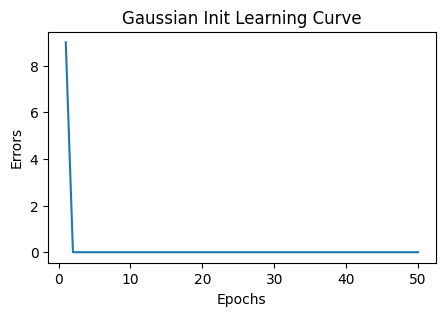

Weights: [-0.32503286 -0.57138264  0.91647689  0.4252303 ]
Bias: -0.1


In [13]:
class PerceptronGaussian:
    def __init__(self, input_dim, lr=0.1, epochs=100, seed=42):
        np.random.seed(seed)
        self.w = np.random.normal(loc=0.0, scale=0.01, size=input_dim)
        self.b = 0.0
        self.lr = lr
        self.epochs = epochs
        self.errors = []

    def predict(self, x):
        return np.where(np.dot(x, self.w) + self.b >= 0.0, 1, 0)

    def train(self, X, y):
        for _ in range(self.epochs):
            err = 0
            for xi, target in zip(X, y):
                update = self.lr * (target - self.predict(xi))
                self.w += update * xi
                self.b += update
                err += int(update != 0.0)
            self.errors.append(err)

p_gaussian = PerceptronGaussian(input_dim=X_train.shape[1], epochs=50)
p_gaussian.train(X_train, y_train)

plt.figure(figsize=(5, 3))
plt.plot(range(1, len(p_gaussian.errors) + 1), p_gaussian.errors)
plt.xlabel('Epochs')
plt.ylabel('Errors')
plt.title('Gaussian Init Learning Curve')
plt.show()

print("Weights:", p_gaussian.w)
print("Bias:", p_gaussian.b)

# Task 5

We implement Xavier/Glorot initialization where weights are sampled with variance dependent on input size, and evaluate the convergence speed.

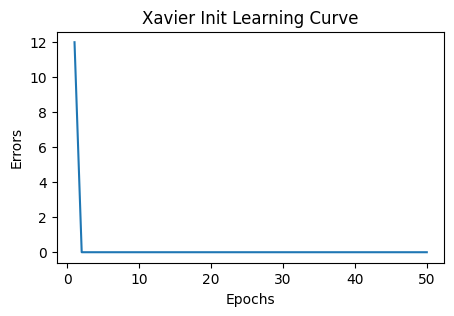

In [14]:
class PerceptronXavier:
    def __init__(self, input_dim, lr=0.1, epochs=100, seed=42):
        np.random.seed(seed)
        limit = np.sqrt(6.0 / (input_dim + 1))
        self.w = np.random.uniform(-limit, limit, size=input_dim)
        self.b = 0.0
        self.lr = lr
        self.epochs = epochs
        self.errors = []

    def predict(self, x):
        return np.where(np.dot(x, self.w) + self.b >= 0.0, 1, 0)

    def train(self, X, y):
        for _ in range(self.epochs):
            err = 0
            for xi, target in zip(X, y):
                update = self.lr * (target - self.predict(xi))
                self.w += update * xi
                self.b += update
                err += int(update != 0.0)
            self.errors.append(err)

p_xavier = PerceptronXavier(input_dim=X_train.shape[1], epochs=50)
p_xavier.train(X_train, y_train)

plt.figure(figsize=(5, 3))
plt.plot(range(1, len(p_xavier.errors) + 1), p_xavier.errors)
plt.xlabel('Epochs')
plt.ylabel('Errors')
plt.title('Xavier Init Learning Curve')
plt.show()

# Task 6

We implement He/Kaiming initialization which scales weights with respect to the input dimension using a standard deviation of sqrt(2/input_dim).

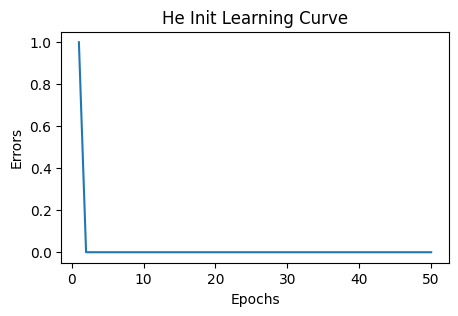

In [15]:
class PerceptronHe:
    def __init__(self, input_dim, lr=0.1, epochs=100, seed=42):
        np.random.seed(seed)
        std = np.sqrt(2.0 / input_dim)
        self.w = np.random.normal(0.0, std, size=input_dim)
        self.b = 0.0
        self.lr = lr
        self.epochs = epochs
        self.errors = []

    def predict(self, x):
        return np.where(np.dot(x, self.w) + self.b >= 0.0, 1, 0)

    def train(self, X, y):
        for _ in range(self.epochs):
            err = 0
            for xi, target in zip(X, y):
                update = self.lr * (target - self.predict(xi))
                self.w += update * xi
                self.b += update
                err += int(update != 0.0)
            self.errors.append(err)

p_he = PerceptronHe(input_dim=X_train.shape[1], epochs=50)
p_he.train(X_train, y_train)

plt.figure(figsize=(5, 3))
plt.plot(range(1, len(p_he.errors) + 1), p_he.errors)
plt.xlabel('Epochs')
plt.ylabel('Errors')
plt.title('He Init Learning Curve')
plt.show()

# Task 7

We implement Orthogonal initialization by generating a random matrix, performing QR decomposition, and utilizing the orthogonal Q matrix columns for weights.

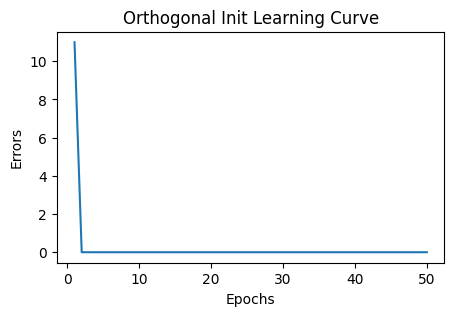

In [16]:
class PerceptronOrthogonal:
    def __init__(self, input_dim, lr=0.1, epochs=100, seed=42):
        np.random.seed(seed)
        q, r = np.linalg.qr(np.random.randn(input_dim, input_dim))
        self.w = q[:, 0]
        self.b = 0.0
        self.lr = lr
        self.epochs = epochs
        self.errors = []

    def predict(self, x):
        return np.where(np.dot(x, self.w) + self.b >= 0.0, 1, 0)

    def train(self, X, y):
        for _ in range(self.epochs):
            err = 0
            for xi, target in zip(X, y):
                update = self.lr * (target - self.predict(xi))
                self.w += update * xi
                self.b += update
                err += int(update != 0.0)
            self.errors.append(err)

p_ortho = PerceptronOrthogonal(input_dim=X_train.shape[1], epochs=50)
p_ortho.train(X_train, y_train)

plt.figure(figsize=(5, 3))
plt.plot(range(1, len(p_ortho.errors) + 1), p_ortho.errors)
plt.xlabel('Epochs')
plt.ylabel('Errors')
plt.title('Orthogonal Init Learning Curve')
plt.show()

# Task 8

We compare all four weight initialization techniques simultaneously on the same training set, plot their combined learning curves, and summarize their performance.

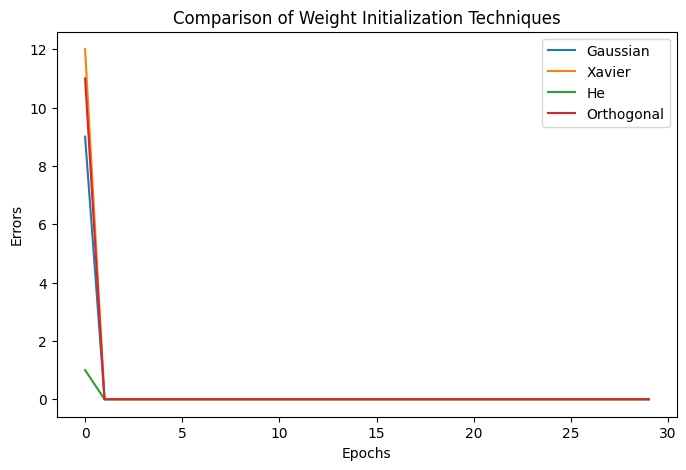

Gaussian final error: 0
Xavier final error: 0
He final error: 0
Orthogonal final error: 0


In [17]:
p_g = PerceptronGaussian(input_dim=X_train.shape[1], epochs=30)
p_g.train(X_train, y_train)

p_x = PerceptronXavier(input_dim=X_train.shape[1], epochs=30)
p_x.train(X_train, y_train)

p_h = PerceptronHe(input_dim=X_train.shape[1], epochs=30)
p_h.train(X_train, y_train)

p_o = PerceptronOrthogonal(input_dim=X_train.shape[1], epochs=30)
p_o.train(X_train, y_train)

plt.figure(figsize=(8, 5))
plt.plot(p_g.errors, label='Gaussian')
plt.plot(p_x.errors, label='Xavier')
plt.plot(p_h.errors, label='He')
plt.plot(p_o.errors, label='Orthogonal')
plt.xlabel('Epochs')
plt.ylabel('Errors')
plt.legend()
plt.title('Comparison of Weight Initialization Techniques')
plt.show()

print("Gaussian final error:", p_g.errors[-1])
print("Xavier final error:", p_x.errors[-1])
print("He final error:", p_h.errors[-1])
print("Orthogonal final error:", p_o.errors[-1])

# Task 9

We perform an experimental study on a second dataset (the Wine dataset, filtering for two classes), evaluating the average convergence epochs over multiple seeds.

In [18]:
from sklearn.datasets import load_wine

wine = load_wine()
X2 = wine.data[wine.target != 2]
y2 = wine.target[wine.target != 2]

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.3, random_state=42)

seeds = [10, 20, 30, 40, 50]
results = {'Gaussian': [], 'Xavier': [], 'He': [], 'Orthogonal': []}

for seed in seeds:
    g = PerceptronGaussian(input_dim=X2_train.shape[1], epochs=50, seed=seed)
    g.train(X2_train, y2_train)
    results['Gaussian'].append(np.mean(g.predict(X2_test) == y2_test))

    x = PerceptronXavier(input_dim=X2_train.shape[1], epochs=50, seed=seed)
    x.train(X2_train, y2_train)
    results['Xavier'].append(np.mean(x.predict(X2_test) == y2_test))

    h = PerceptronHe(input_dim=X2_train.shape[1], epochs=50, seed=seed)
    h.train(X2_train, y2_train)
    results['He'].append(np.mean(h.predict(X2_test) == y2_test))

    o = PerceptronOrthogonal(input_dim=X2_train.shape[1], epochs=50, seed=seed)
    o.train(X2_train, y2_train)
    results['Orthogonal'].append(np.mean(o.predict(X2_test) == y2_test))

for k, v in results.items():
    print(f"{k} - Average Accuracy across seeds: {np.mean(v):.4f}")

Gaussian - Average Accuracy across seeds: 0.8462
Xavier - Average Accuracy across seeds: 0.8564
He - Average Accuracy across seeds: 0.8513
Orthogonal - Average Accuracy across seeds: 0.8513
